## Risk Pipeline & Heatmap Generator Function

In [1]:
import os
import time
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import AutoImageProcessor, AutoModelForDepthEstimation
from ultralytics import YOLO

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
PROJECT_ROOT = os.path.abspath("..")
EXCEL_PATH = os.path.join(PROJECT_ROOT, "notebooks", "experiment_results.xlsx")
HEATMAP_DIR = os.path.join(PROJECT_ROOT, "outputs", "heatmaps")
os.makedirs(HEATMAP_DIR, exist_ok=True)

# Load Models
seg_model = YOLO("yolo11n-seg.pt")
depth_encoder = "depth-anything/Depth-Anything-V2-Small-hf"
depth_processor = AutoImageProcessor.from_pretrained(depth_encoder)
depth_model = AutoModelForDepthEstimation.from_pretrained(depth_encoder).to(
    device
)

# Class Weights (W_class) mapping
CLASS_WEIGHTS = {
    "person": 1.00,
    "bicycle": 0.90,
    "motorcycle": 0.85,
    "car": 0.70,
    "bus": 0.60,
    "truck": 0.60,
    "traffic cone": 0.30,
    "barrier": 0.30,
}


def generate_risk_heatmap(image_path, scene_label):
    raw_img = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB)
    h, w, _ = raw_img.shape

    # 1. Depth Estimation
    inputs = depth_processor(images=img_rgb, return_tensors="pt").to(device)
    with torch.no_grad():
        depth_out = depth_model(**inputs)
        pred_depth = depth_out.predicted_depth

    depth_map = (
        torch.nn.functional.interpolate(
            pred_depth.unsqueeze(1),
            size=(h, w),
            mode="bicubic",
            align_corners=False,
        )
        .squeeze()
        .cpu()
        .numpy()
    )

    # Normalize depth map to relative distance (0.1m to 50m clip)
    depth_meters = np.clip((1.0 / (depth_map + 1e-6)) * 10.0, 0.5, 50.0)

    # 2. YOLO Segmentation
    results = seg_model.predict(source=image_path, device=device, verbose=False)[
        0
    ]

    # Initialize 2D Spatial Risk Density Grid
    spatial_risk_map = np.zeros((h, w), dtype=np.float32)
    detected_objects = []

    if results.masks is not None:
        masks = results.masks.data.cpu().numpy()
        boxes = results.boxes

        for i, mask in enumerate(masks):
            class_id = int(boxes.cls[i].item())
            class_name = results.names[class_id]
            conf = float(boxes.conf[i].item())

            # Resize mask to image dimensions
            mask_resized = cv2.resize(mask, (w, h)) > 0.5
            if not np.any(mask_resized):
                continue

            # Calculate object distance (median pixel value in mask)
            obj_distance = float(np.median(depth_meters[mask_resized]))

            # Class risk weight W_class (default 0.4 if unlisted)
            w_class = CLASS_WEIGHTS.get(class_name, 0.40)

            # Proximity Risk Equation: R_prox = W_class * (1 / distance)
            proximity_risk = w_class * (10.0 / (obj_distance + 1e-3))

            # Accumulate risk onto 2D spatial map
            spatial_risk_map[mask_resized] += proximity_risk

            detected_objects.append({
                "class": class_name,
                "w_class": w_class,
                "distance_m": round(obj_distance, 2),
                "risk": round(proximity_risk, 3),
            })

    # Normalize heatmap overlay
    norm_risk = cv2.normalize(
        spatial_risk_map, None, 0, 255, cv2.NORM_MINMAX
    ).astype(np.uint8)
    heatmap_color = cv2.applyColorMap(norm_risk, cv2.COLORMAP_JET)
    heatmap_rgb = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)

    # Overlay heatmap on original frame (alpha blending)
    overlay = cv2.addWeighted(img_rgb, 0.6, heatmap_rgb, 0.4, 0)

    # Visualization plot
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    axes[0].imshow(img_rgb)
    axes[0].set_title(f"Input Frame: {scene_label}", fontsize=12)
    axes[0].axis("off")

    im = axes[1].imshow(overlay)
    axes[1].set_title(
        f"Qualitative Risk Heatmap ({scene_label})", fontsize=12
    )
    axes[1].axis("off")

    output_fig_path = os.path.join(
        HEATMAP_DIR, f"heatmap_{scene_label.replace(' ', '_').lower()}.png"
    )
    plt.tight_layout()
    plt.savefig(output_fig_path, dpi=300)
    plt.show()

    return detected_objects, output_fig_path

/opt/anaconda3/envs/av_risk/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 287/287 [00:00<00:00, 7545.84it/s]


## Run Experiments Across Scenarios

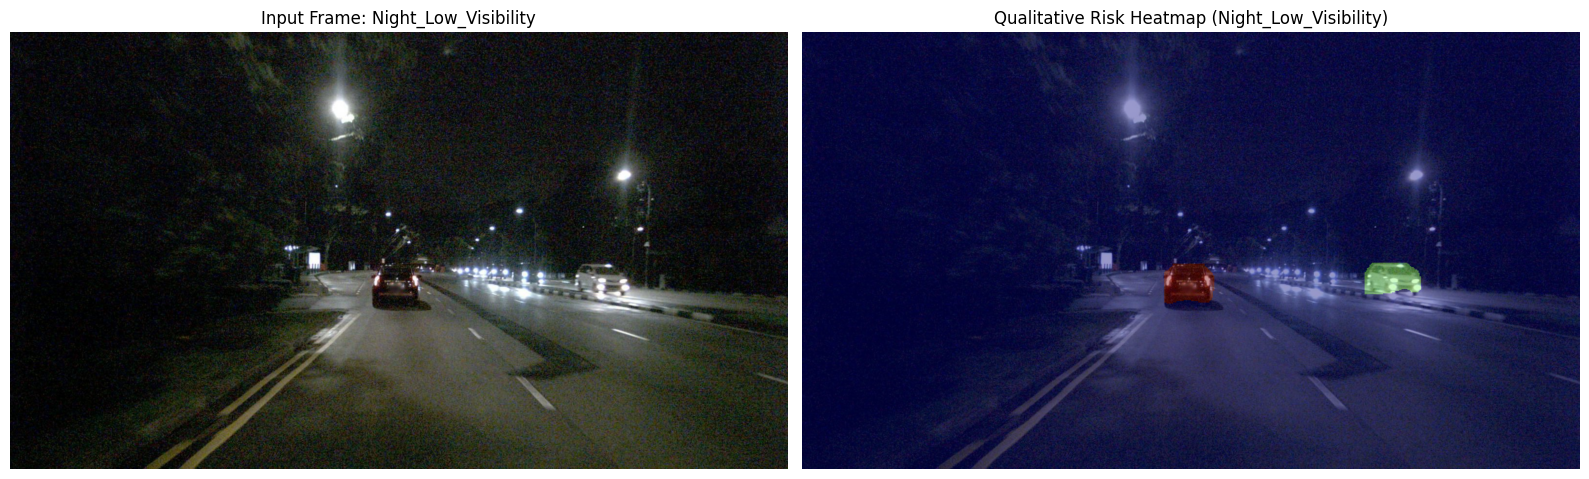

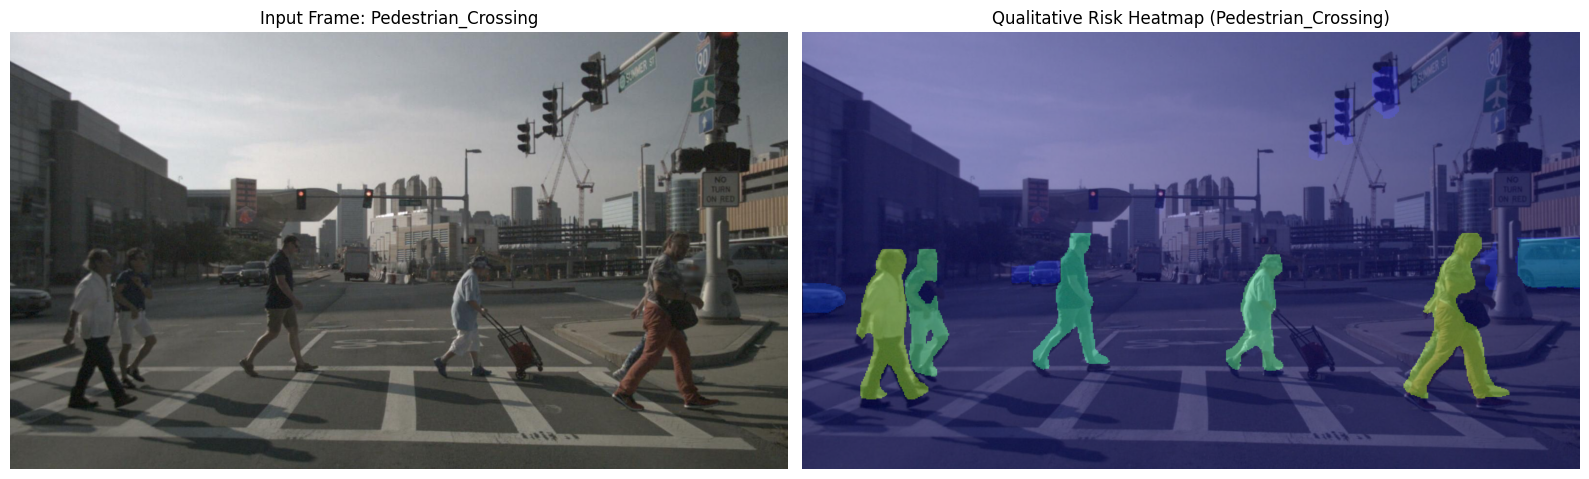

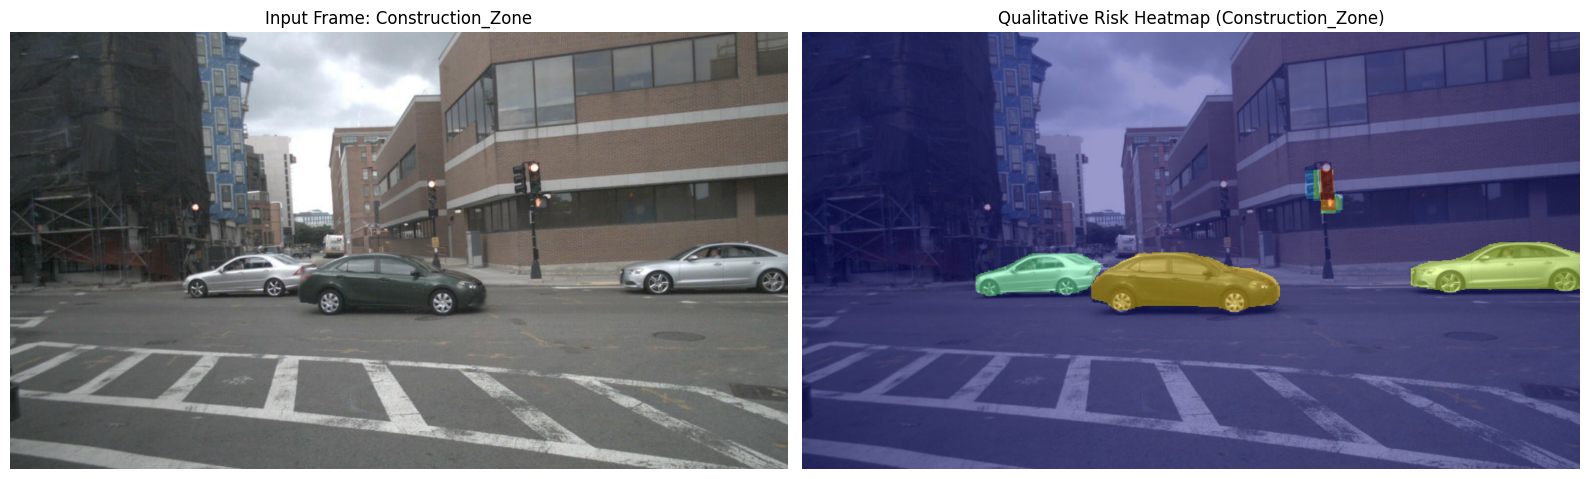

Qualitative scenario evaluation completed.


In [8]:
# Map driving scenario frames (update filenames matching your local CAM_FRONT path)
test_scenarios = {
    "Night_Low_Visibility": "n008-2018-08-01-15-16-36-0400__CAM_FRONT__153315109.jpg",  # replace with night frame
    "Pedestrian_Crossing": "n008-2018-08-28-16-43-51-0400__CAM_FRONT__1535489308362404.jpg",  # replace with ped frame
    "Construction_Zone": "n008-2018-08-30-15-16-55-0400__CAM_FRONT__1535657123612404.jpg",  # replace with cone/barrier frame
}

scenario_summaries = []

for label, img_name in test_scenarios.items():
    full_path = os.path.join(
        PROJECT_ROOT, "v1.0-mini", "samples", "CAM_FRONT", img_name
    )

    if not os.path.exists(full_path):
        # Fallback to first available frame in sample directory if exact frame missing
        avail = [
            f
            for f in os.listdir(
                os.path.join(PROJECT_ROOT, "v1.0-mini", "samples", "CAM_FRONT")
            )
            if f.endswith(".jpg")
        ]
        full_path = os.path.join(
            PROJECT_ROOT, "v1.0-mini", "samples", "CAM_FRONT", avail[0]
        )

    objs, saved_path = generate_risk_heatmap(full_path, label)
    max_risk = max([o["risk"] for o in objs]) if objs else 0.0

    scenario_summaries.append({
        "Scenario": label,
        "Total_Objects": len(objs),
        "Peak_Risk_Score": max_risk,
        "Heatmap_Saved": saved_path,
    })

print("Qualitative scenario evaluation completed.")

## Generate Comparative Performance Tables

In [10]:
# 1. Load experiment logs
if os.path.exists(EXCEL_PATH):
    df_logs = pd.read_excel(EXCEL_PATH)

    df_summary = (
        df_logs.groupby("Task")
        .agg(
            Avg_Latency_ms=("Latency_ms", "mean"),
            Min_Latency_ms=("Latency_ms", "min"),
            Avg_FPS=("FPS", "mean"),
            Avg_Peak_Risk=("Max_Risk_Score", "mean"),
        )
        .reset_index()
    )

    print("=== ARCHITECTURAL COMPARISON TABLE ===")
    display(df_summary.round(2))

# Display scenario qualitative summary
df_scenarios = pd.DataFrame(scenario_summaries)
print("\n=== SCENARIO EVALUATION SUMMARY ===")
display(df_scenarios)

=== ARCHITECTURAL COMPARISON TABLE ===


,Task,Avg_Latency_ms,Min_Latency_ms,Avg_FPS,Avg_Peak_Risk
0,Approach A - Early/Late Parallel Fusion,770.58,289.10,2.42,4.89
1,Approach B - Motion-Aware Dynamic/Static,2584.20,552.64,1.02,127.69
2,Approach C - End-to-End Feature Fusion,2465.53,357.98,1.50,1.20
3,Instance Segmentation,NaN,NaN,NaN,NaN
4,Segmentation,NaN,NaN,NaN,NaN
5,Segmentation Comparison,NaN,NaN,NaN,NaN



=== SCENARIO EVALUATION SUMMARY ===


,Scenario,Total_Objects,Peak_Risk_Score,Heatmap_Saved
0,Night_Low_Visibility,2,1.155,/Users/anupamahalder/Autonomous_Vehicle_Risk_E...
1,Pedestrian_Crossing,16,4.584,/Users/anupamahalder/Autonomous_Vehicle_Risk_E...
2,Construction_Zone,8,2.321,/Users/anupamahalder/Autonomous_Vehicle_Risk_E...
